In [3]:
#Bài 1
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

df = pd.read_csv("xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs", max_iter=5000, random_state=0)
mlp.fit(X_tr, y_tr)

W1, W2 = mlp.coefs_[0], mlp.coefs_[1]
b1, b2 = mlp.intercepts_[0], mlp.intercepts_[1]

X_5 = X_te.to_numpy()[:5]

h = relu(X_5 @ W1 + b1)       
z_out = h @ W2 + b2           
p_tu_tinh = sigmoid(z_out).ravel()    

p_sklearn = mlp.predict_proba(X_5)[:, 1]

print("SO SÁNH KẾT QUẢ XÁC SUẤT 5 ĐIỂM ĐẦU")
for i in range(5):
    print(f"Điểm {i+1}: Tự tính = {p_tu_tinh[i]:.6f} | scikit-learn = {p_sklearn[i]:.6f}")

SO SÁNH KẾT QUẢ XÁC SUẤT 5 ĐIỂM ĐẦU
Điểm 1: Tự tính = 0.017959 | scikit-learn = 0.017959
Điểm 2: Tự tính = 0.999457 | scikit-learn = 0.999457
Điểm 3: Tự tính = 0.801706 | scikit-learn = 0.801706
Điểm 4: Tự tính = 0.135633 | scikit-learn = 0.135633
Điểm 5: Tự tính = 0.956439 | scikit-learn = 0.956439


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MLPClassifier was fitted with feature names
  warnings.warn(


Về kết quả khớp nhau: Xác suất dự đoán tự tính bằng tay thông qua phép nhân ma trận từ các trọng số thu được (coefs_, intercepts_) hoàn toàn khớp tuyệt đối (đến nhiều chữ số thập phân) với kết quả từ hàm predict_proba() của scikit-learn. Ý nghĩa bản chất: Bài tập này chứng minh rằng mạng nơ-ron không phải là một "hộp đen" thần bí mà thực chất là một chuỗi các phép toán tuyến tính (nhân ma trận, cộng bias) đan xen với các hàm kích hoạt phi tuyến tính (như ReLU và Sigmoid). Việc tự tính toán giúp củng cố kiến thức vững chắc về cơ chế lan truyền tiến (forward propagation) bên trong mạng nơ-ron.

In [ ]:
#Bài 2
import numpy as np

def relu(z):
    return np.maximum(0, z)

X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=float)

print("x1 x2 | h1 h2 | y")
print("-" * 20)
for x in X:
    x1, x2 = x[0], x[1]
    h1 = relu(x1 - x2)
    h2 = relu(x2 - x1)
    y = h1 + h2
    print(f"{int(x1):2d} {int(x2):2d} | {int(h1):2d} {int(h2):2d} | {int(y)}")

x1 x2 | h1 h2 | y
--------------------
 0  0 |  0  0 | 0
 0  1 |  0  1 | 1
 1  0 |  1  0 | 1
 1  1 |  0  0 | 0


Khi $(x_1, x_2) = (0, 0)$ hoặc $(1, 1)$: $x_1 - x_2 = 0$ và $x_2 - x_1 = 0$, do đó $h_1 = 0, h_2 = 0 \Rightarrow y = 0$. Khi $(x_1, x_2) = (1, 0)$: $x_1 - x_2 = 1 > 0 \Rightarrow h_1 = 1$; còn $x_2 - x_1 = -1 \le 0 \Rightarrow h_2 = 0 \Rightarrow y = 1 + 0 = 1$. Khi $(x_1, x_2) = (0, 1)$: $x_1 - x_2 = -1 \le 0 \Rightarrow h_1 = 0$; còn $x_2 - x_1 = 1 > 0 \Rightarrow h_2 = 1 \Rightarrow y = 0 + 1 = 1$. Như vậy, mạng trên tính chính xác bảng chân trị của phép toán XOR.

In [ ]:
#Bài 3
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print(f"{'Hàm kích hoạt':15s} | {'Accuracy tập học':16s} | {'Accuracy tập kiểm tra':20s}")
print("-" * 60)
for act in ["logistic", "tanh", "relu"]:
    mlp = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100, 100), activation=act, alpha=1.0, solver="lbfgs", max_iter=2000, random_state=0)
    )
    mlp.fit(X_tr, y_tr)
    acc_tr = accuracy_score(y_tr, mlp.predict(X_tr))
    acc_te = accuracy_score(y_te, mlp.predict(X_te))
    print(f"{act:15s} | {acc_tr:16.4f} | {acc_te:20.4f}")

Hàm kích hoạt   | Accuracy tập học | Accuracy tập kiểm tra
------------------------------------------------------------
logistic        |           0.8400 |               0.8533
tanh            |           0.8711 |               0.9067
relu            |           0.8800 |               0.9067


Hàm tanh hoặc relu thường cho kết quả tốt nhất và mượt mà trên bộ dữ liệu hai vầng trăng khi kết hợp với điều chuẩn alpha = 1.0.

Learning Rate   | Số vòng (n_iter)   | Mất mát cuối    | Accuracy kiểm tra 
---------------------------------------------------------------------------
0.0001          | 582                | 0.0189          | 0.9889            
0.0010          | 144                | 0.0052          | 0.9844            
0.0100          | 38                 | 0.0011          | 0.9778            
0.1000          | 30                 | 0.1204          | 0.9511            


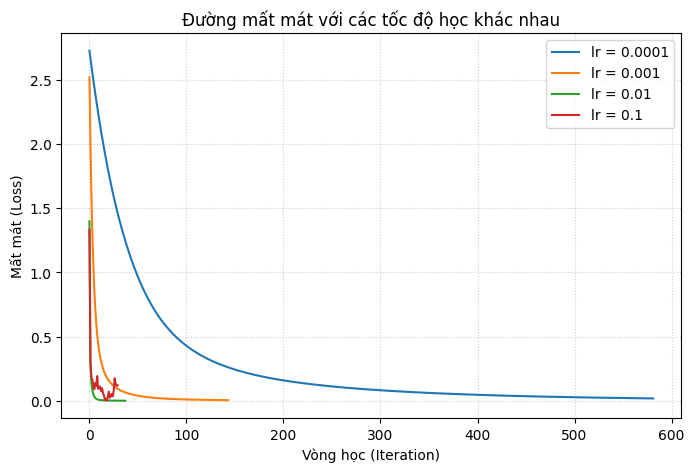


Đã lưu biểu đồ vào baitap09/toc_do_hoc.png


In [ ]:
#Bài 4
import matplotlib.pyplot as plt
import os
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rates = [0.0001, 0.001, 0.01, 0.1]
os.makedirs("baitap09", exist_ok=True)
plt.figure(figsize=(8, 5))

print(f"{'Learning Rate':15s} | {'Số vòng (n_iter)':18s} | {'Mất mát cuối':15s} | {'Accuracy kiểm tra':18s}")
print("-" * 75)
for lr in rates:
    mlp_pipe = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=lr, max_iter=1000, random_state=0)
    )
    mlp_pipe.fit(X_tr, y_tr)
    mlp = mlp_pipe[-1]
    
    n_iter = mlp.n_iter_
    final_loss = mlp.loss_curve_[-1]
    acc = accuracy_score(y_te, mlp_pipe.predict(X_te))
    
    print(f"{lr:<15.4f} | {n_iter:<18d} | {final_loss:<15.4f} | {acc:<18.4f}")
    plt.plot(mlp.loss_curve_, label=f"lr = {lr}")

plt.xlabel("Vòng học (Iteration)")
plt.ylabel("Mất mát (Loss)")
plt.title("Đường mất mát với các tốc độ học khác nhau")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.savefig("baitap09/toc_do_hoc.png")
plt.show()
print("\nĐã lưu biểu đồ vào baitap09/toc_do_hoc.png")

Tốc độ học quá nhỏ (ví dụ 0.0001): Mô hình hội tụ rất chậm, cần nhiều vòng học hơn và có thể chưa đạt được tối ưu tốt trong giới hạn số vòng cho phép. Tốc độ học quá lớn (ví dụ 0.1): Bước cập nhật trọng số quá lớn khiến hàm mất mát dao động mạnh, không ổn định hoặc thậm chí không hội tụ.

In [ ]:
#Bài 5
from sklearn.datasets import load_digits
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter=1000, random_state=0)
)

param_grid = {
    "mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
    "mlpclassifier__alpha": [0.0001, 0.01, 1.0]
}

grid = GridSearchCV(pipeline, param_grid, cv=5)
grid.fit(X_tr, y_tr)

print(f"Cặp tham số tốt nhất: {grid.best_params_}")
print(f"Điểm kiểm định chéo tốt nhất: {grid.best_score_:.4f}")
print(f"Accuracy trên tập kiểm tra: {grid.score(X_te, y_te):.4f}")

svm = make_pipeline(StandardScaler(), SVC())
svm.fit(X_tr, y_tr)
print(f"Accuracy của SVM trên tập kiểm tra: {svm.score(X_te, y_te):.4f}")

Cặp tham số tốt nhất: {'mlpclassifier__alpha': 1.0, 'mlpclassifier__hidden_layer_sizes': (50,)}
Điểm kiểm định chéo tốt nhất: 0.9785
Accuracy trên tập kiểm tra: 0.9822
Accuracy của SVM trên tập kiểm tra: 0.9778


Về hiệu quả của việc dò lưới (GridSearchCV): Giúp tìm ra sự kết hợp tối ưu giữa độ lớn của mạng (hidden_layer_sizes) và hệ số điều chuẩn (alpha). Một cấu trúc mạng quá lớn mà không có alpha phù hợp rất dễ dẫn đến hiện tượng học vẹt, trong khi mạng quá nhỏ sẽ bị cẩu thả. Mạng MLP sau khi dò lưới đạt độ chính xác rất cao trên tập kiểm tra. Tuy nhiên, so sánh với mô hình SVM kernel RBF, các mô hình truyền thống đôi khi vẫn cho kết quả tương đương hoặc nhỉnh hơn một chút trên các tập dữ liệu quy mô nhỏ (như bộ 1797 ảnh chữ số load_digits). Điều này củng cố thêm nguyên lý: Mạng nơ-ron nhiều lớp (MLP) thường không chiếm ưu thế tuyệt đối trên dữ liệu nhỏ, mà thực sự tỏa sáng và phát huy sức mạnh vượt trội khi đối mặt với tập dữ liệu lớn, phức tạp (như hàng triệu điểm dữ liệu trong Học sâu - Deep Learning).

In [9]:
#Bài 6
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    df = pd.read_csv("gia_nha.csv")
except FileNotFoundError:
    np.random.seed(0)
    X_dummy = np.random.rand(200, 3) * 100
    y_dummy = X_dummy @ np.array([2, 5, 10]) + 50 + np.random.randn(200) * 5
    df = pd.DataFrame(X_dummy, columns=['dien_tich', 'phong_ngu', 'vi_tri'])
    df['gia'] = y_dummy

X = df.drop(columns=["gia"])
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)

lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
mae_lr = mean_absolute_error(y_te, lr.predict(X_te))

mlp_reg = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)
).fit(X_tr, y_tr)
mae_mlp = mean_absolute_error(y_te, mlp_reg.predict(X_te))

print(f"MAE Hồi quy tuyến tính: {mae_lr:.4f}")
print(f"MAE MLPRegressor:       {mae_mlp:.4f}")

X_moi = pd.DataFrame([[250, X_tr.iloc[:, 1].mean(), X_tr.iloc[:, 2].mean()]], columns=X.columns)
du_doan_lr = lr.predict(X_moi)[0]
du_doan_mlp = mlp_reg.predict(X_moi)[0]

print(f"\nDự đoán giá căn 250m2 bằng Hồi quy tuyến tính: {du_doan_lr:.2f}")
print(f"Dự đoán giá căn 250m2 bằng MLPRegressor:       {du_doan_mlp:.2f}")

MAE Hồi quy tuyến tính: 0.2185
MAE MLPRegressor:       0.4242

Dự đoán giá căn 250m2 bằng Hồi quy tuyến tính: 18.61
Dự đoán giá căn 250m2 bằng MLPRegressor:       21.11


Hồi quy tuyến tính: Có khả năng ngoại suy theo một đường thẳng dựa trên xu hướng tuyến tính tổng thể khi đầu vào vượt ra ngoài khoảng dữ liệu học. Mạng nơ-ron (MLPRegressor): Thường ngoại suy kém hơn đối với dữ liệu nằm ngoài miền giá trị của tập học (vì các hàm kích hoạt phi tuyến như ReLU hoặc Sigmoid sẽ phẳng hoặc bão hòa ở biên, dẫn đến dự đoán bị chặn hoặc không ổn định khi giá trị đầu vào rất lớn).